In [1]:
import math

from PIL import Image
import requests
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'retina'

import ipywidgets as widgets
from IPython.display import display, clear_output

import torch
from torch import nn
from torchvision.models import resnet50
import torchvision.transforms as T
torch.set_grad_enabled(False);

In [2]:
CLASSES = [
    'N/A', 'person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus',
    'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'N/A',
    'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse',
    'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'N/A', 'backpack',
    'umbrella', 'N/A', 'N/A', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis',
    'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove',
    'skateboard', 'surfboard', 'tennis racket', 'bottle', 'N/A', 'wine glass',
    'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich',
    'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake',
    'chair', 'couch', 'potted plant', 'bed', 'N/A', 'dining table', 'N/A',
    'N/A', 'toilet', 'N/A', 'tv', 'laptop', 'mouse', 'remote', 'keyboard',
    'cell phone', 'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'N/A',
    'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier',
    'toothbrush'
]

# colors for visualization
COLORS = [[0.000, 0.447, 0.741], [0.850, 0.325, 0.098], [0.929, 0.694, 0.125],
          [0.494, 0.184, 0.556], [0.466, 0.674, 0.188], [0.301, 0.745, 0.933]]

In [3]:
from data.dataloader import get_dataloader

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [16]:
# standard PyTorch mean-std input image normalization
transform = T.Compose([
    T.Resize(800)
])

# for output bounding box post-processing
def box_cxcywh_to_xyxy(x):
    x_c, y_c, w, h = x.unbind(1)
    b = [(x_c - 0.5 * w), (y_c - 0.5 * h),
         (x_c + 0.5 * w), (y_c + 0.5 * h)]
    return torch.stack(b, dim=1)

def rescale_bboxes(out_bbox, size):
    img_w, img_h = size
    b = box_cxcywh_to_xyxy(out_bbox)
    b = b * torch.tensor([img_w, img_h, img_w, img_h], dtype=torch.float32)
    return b

def plot_results(pil_img, prob, boxes):
    plt.figure(figsize=(16,10))
    plt.imshow(pil_img)
    ax = plt.gca()
    colors = COLORS * 100
    for p, (xmin, ymin, xmax, ymax), c in zip(prob, boxes.tolist(), colors):
        ax.add_patch(plt.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin,
                                   fill=False, color=c, linewidth=3))
        cl = p.argmax()
        text = f'{CLASSES[cl]}: {p[cl]:0.2f}'
        ax.text(xmin, ymin, text, fontsize=15,
                bbox=dict(facecolor='yellow', alpha=0.5))
    plt.axis('off')
    plt.show()

In [6]:
model = torch.hub.load('facebookresearch/detr', 'detr_resnet50', pretrained=True)
model.eval();

Downloading: "https://github.com/facebookresearch/detr/zipball/main" to /home/hertrich/.cache/torch/hub/main.zip
/home/hertrich/miniconda3/envs/nanofm/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/hertrich/miniconda3/envs/nanofm/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /home/hertrich/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100%|███████████████████████████████████████████████████████████████

In [7]:
from types import SimpleNamespace

config = SimpleNamespace()
config.data = SimpleNamespace()
config.data.dataset_name = "JierunChen/Ref-L4"
config.data.split = "val"
config.data.load_images = True
config.data.load_features = False
config.data.feature_path = "./data/longclip-emb"
config.data.batch_size = 1
config.data.shuffle = False
config.data.num_workers = 1

In [8]:
full_ds, inference_loader = get_dataloader(config)

INFO:root:Loading images from /home/hertrich/.cache/huggingface/hub/datasets--JierunChen--Ref-L4/snapshots/d62c4f4e5f3a639b34adab34e5c8ffeb39f168c1/images.tar.gz


Downloaded images.tar.gz to /home/hertrich/.cache/huggingface/hub/datasets--JierunChen--Ref-L4/snapshots/d62c4f4e5f3a639b34adab34e5c8ffeb39f168c1/images.tar.gz


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 9735/9735 [00:14<00:00, 671.54it/s]


In [13]:
num_of_examples = 4

Image shape:  torch.Size([1, 3, 224, 224])
Image shape after selection:  torch.Size([3, 224, 224])


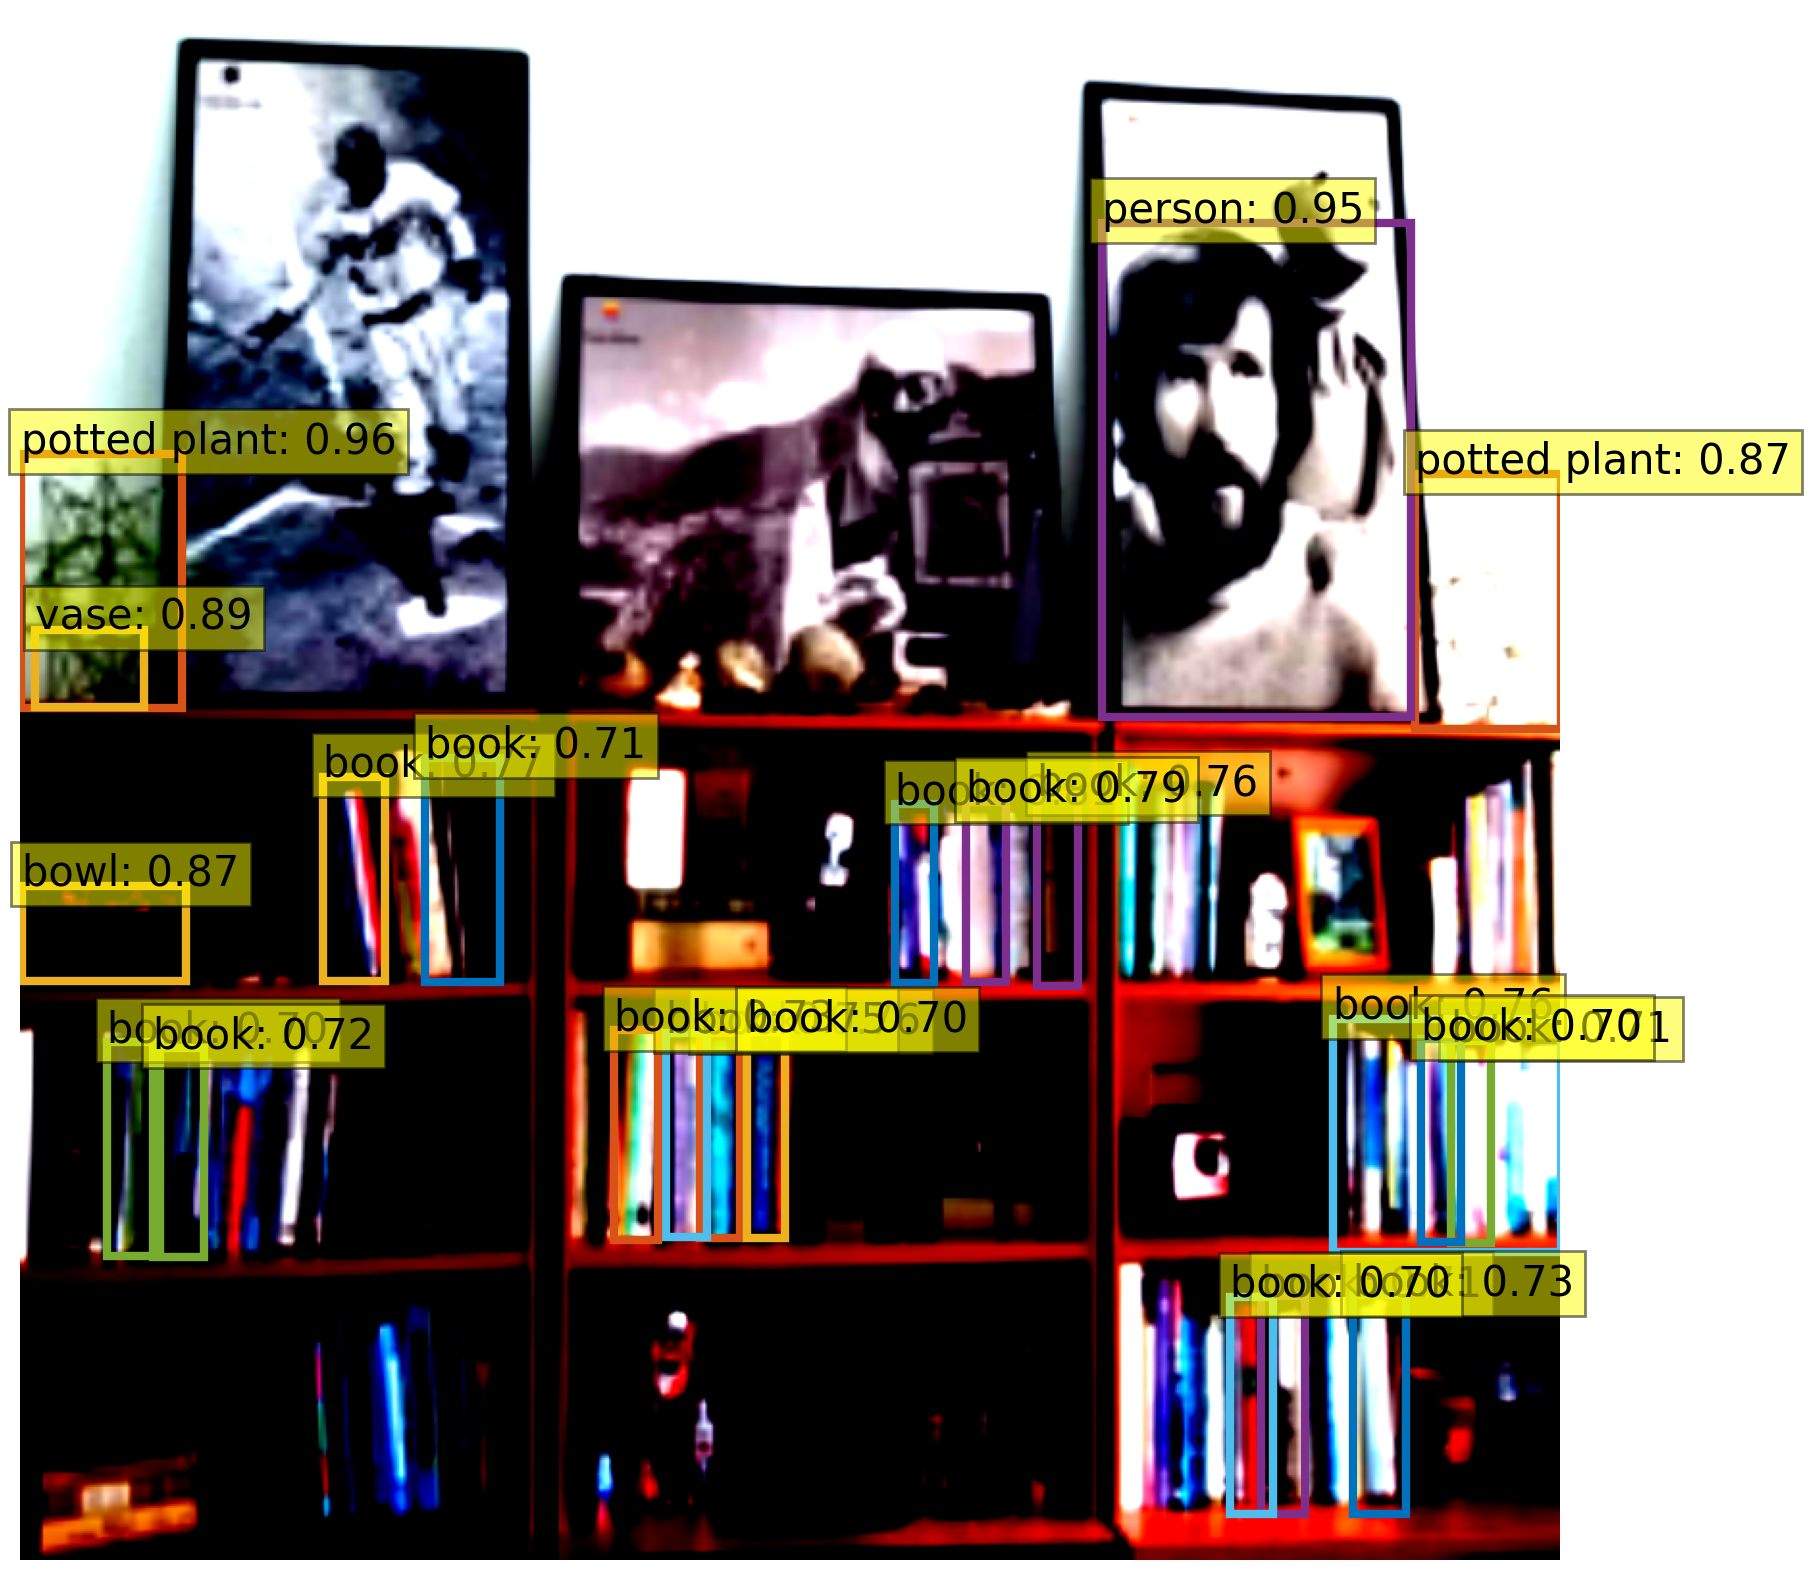

Image shape:  torch.Size([1, 3, 224, 224])
Image shape after selection:  torch.Size([3, 224, 224])


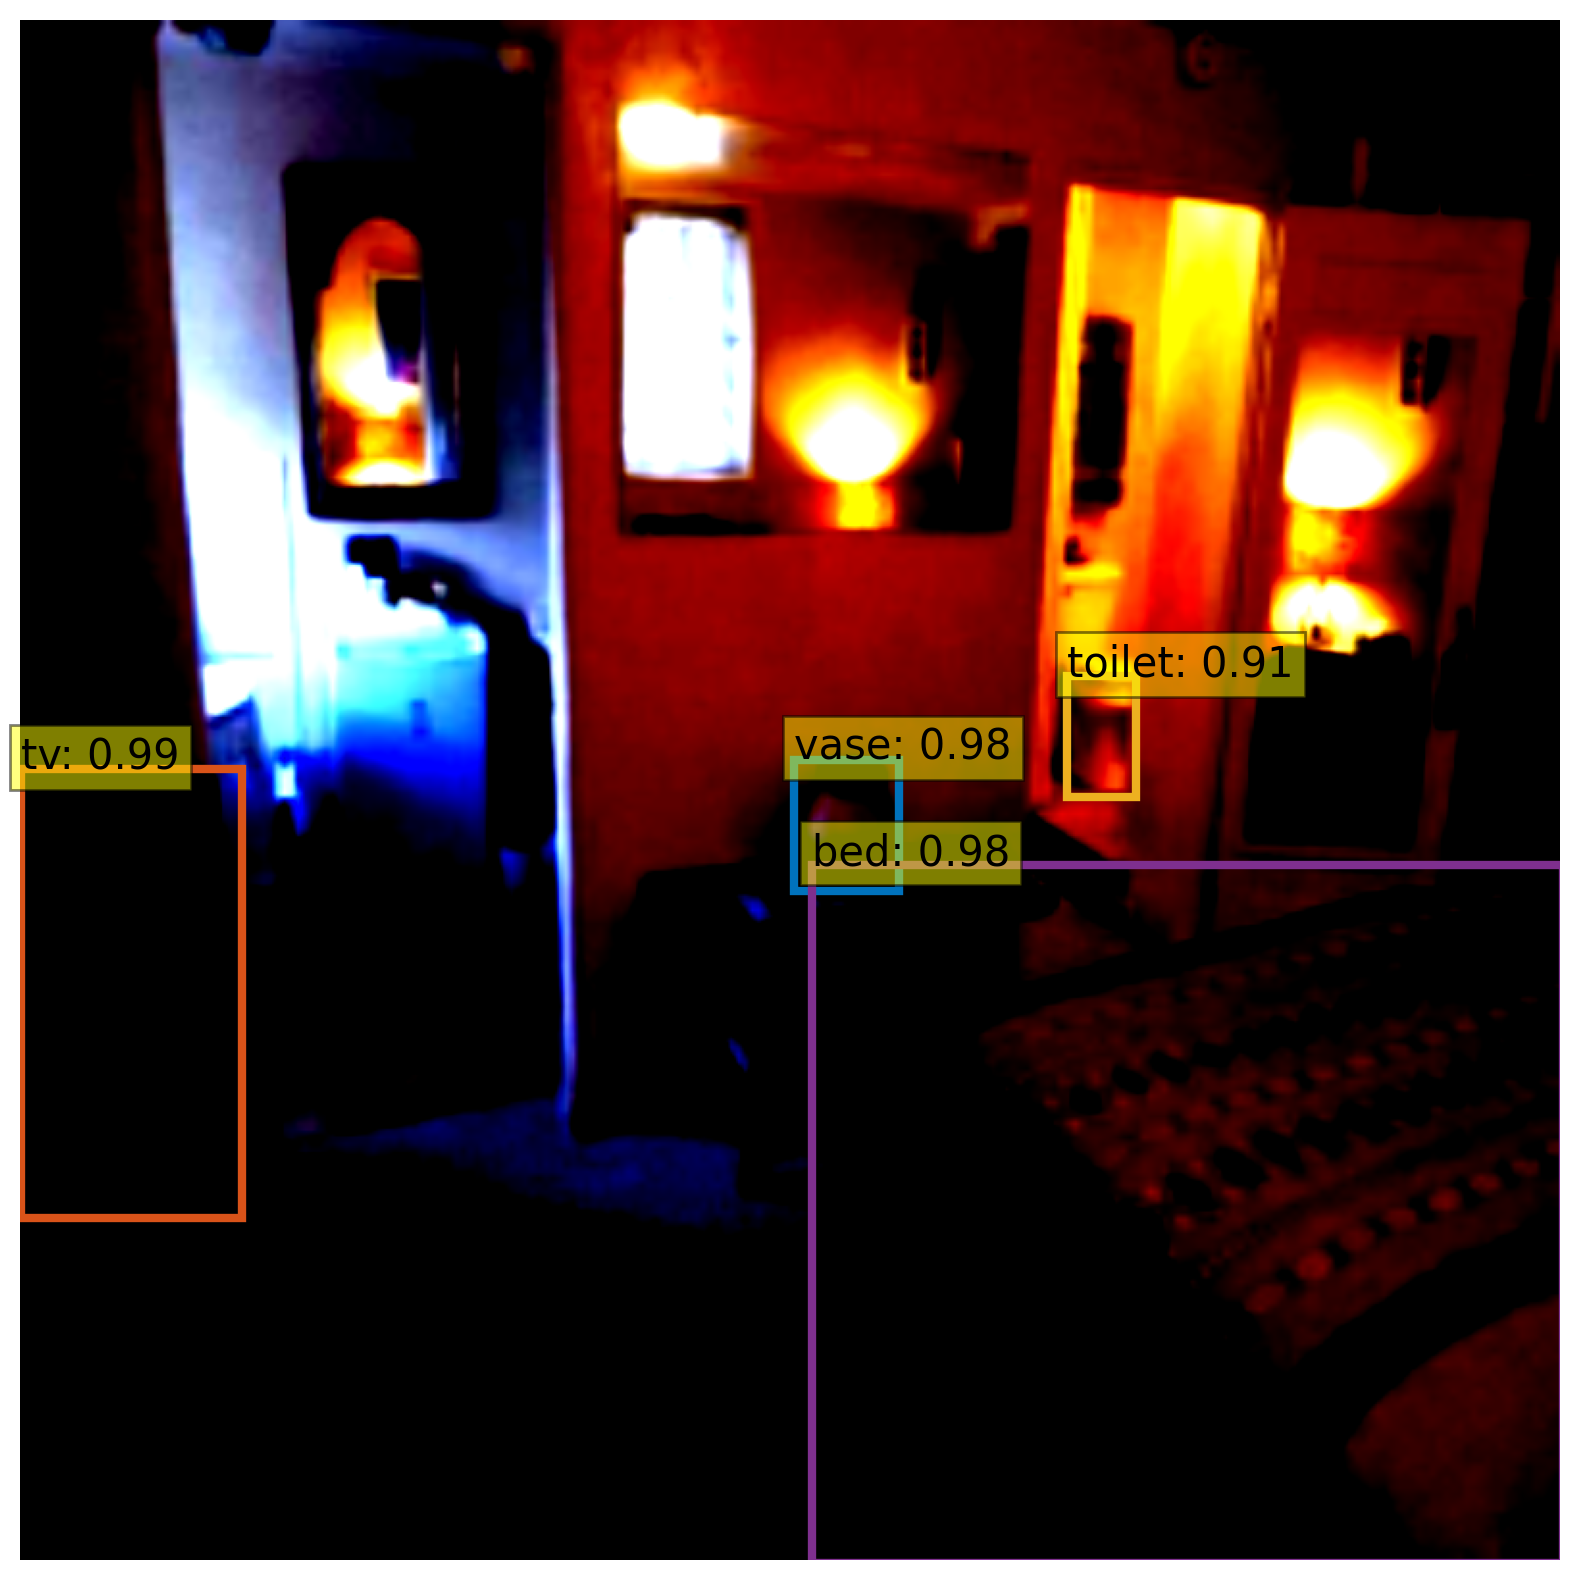

Image shape:  torch.Size([1, 3, 224, 224])
Image shape after selection:  torch.Size([3, 224, 224])


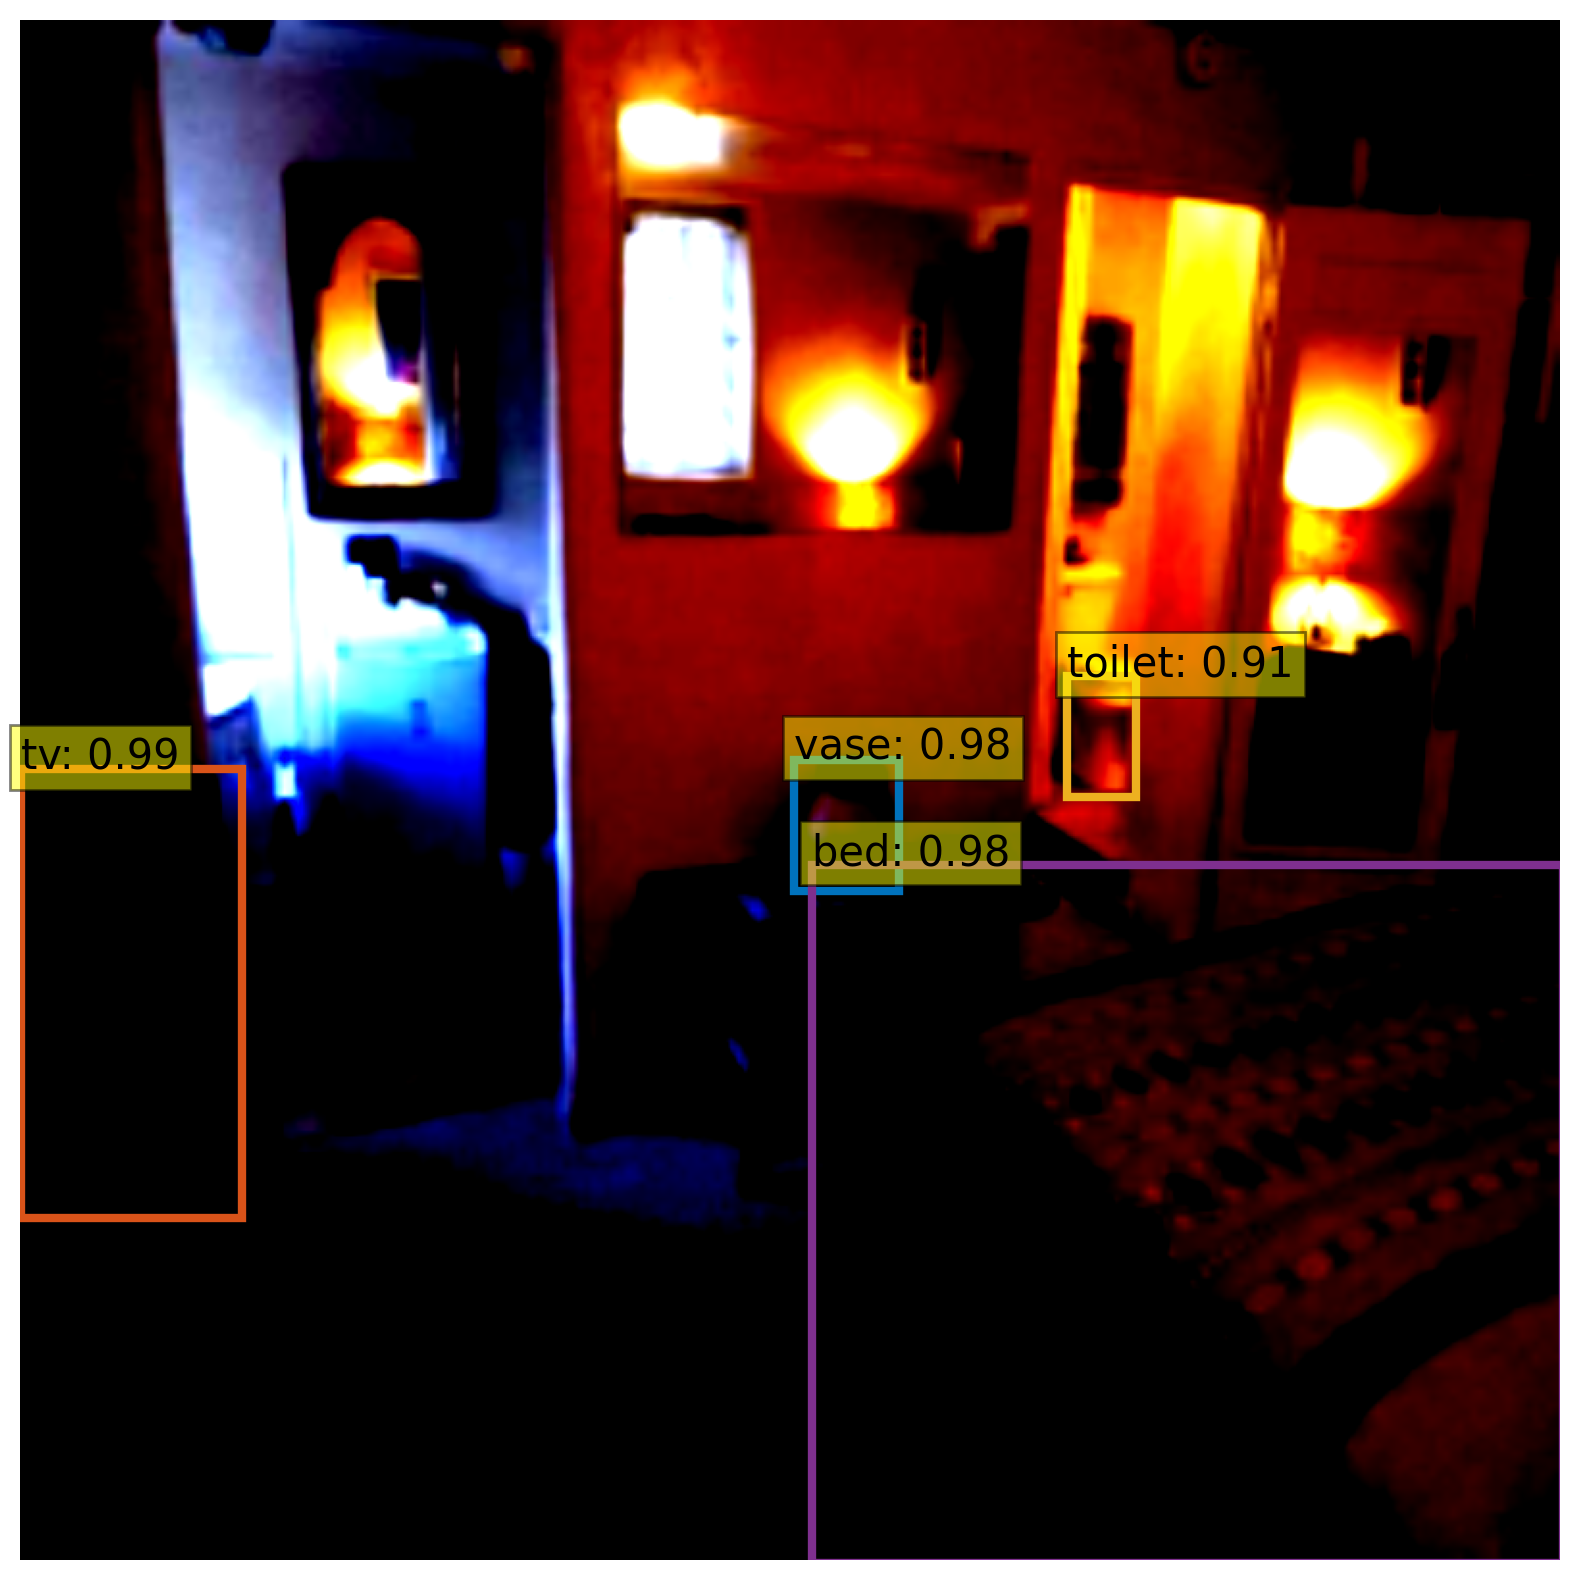

Image shape:  torch.Size([1, 3, 224, 224])
Image shape after selection:  torch.Size([3, 224, 224])


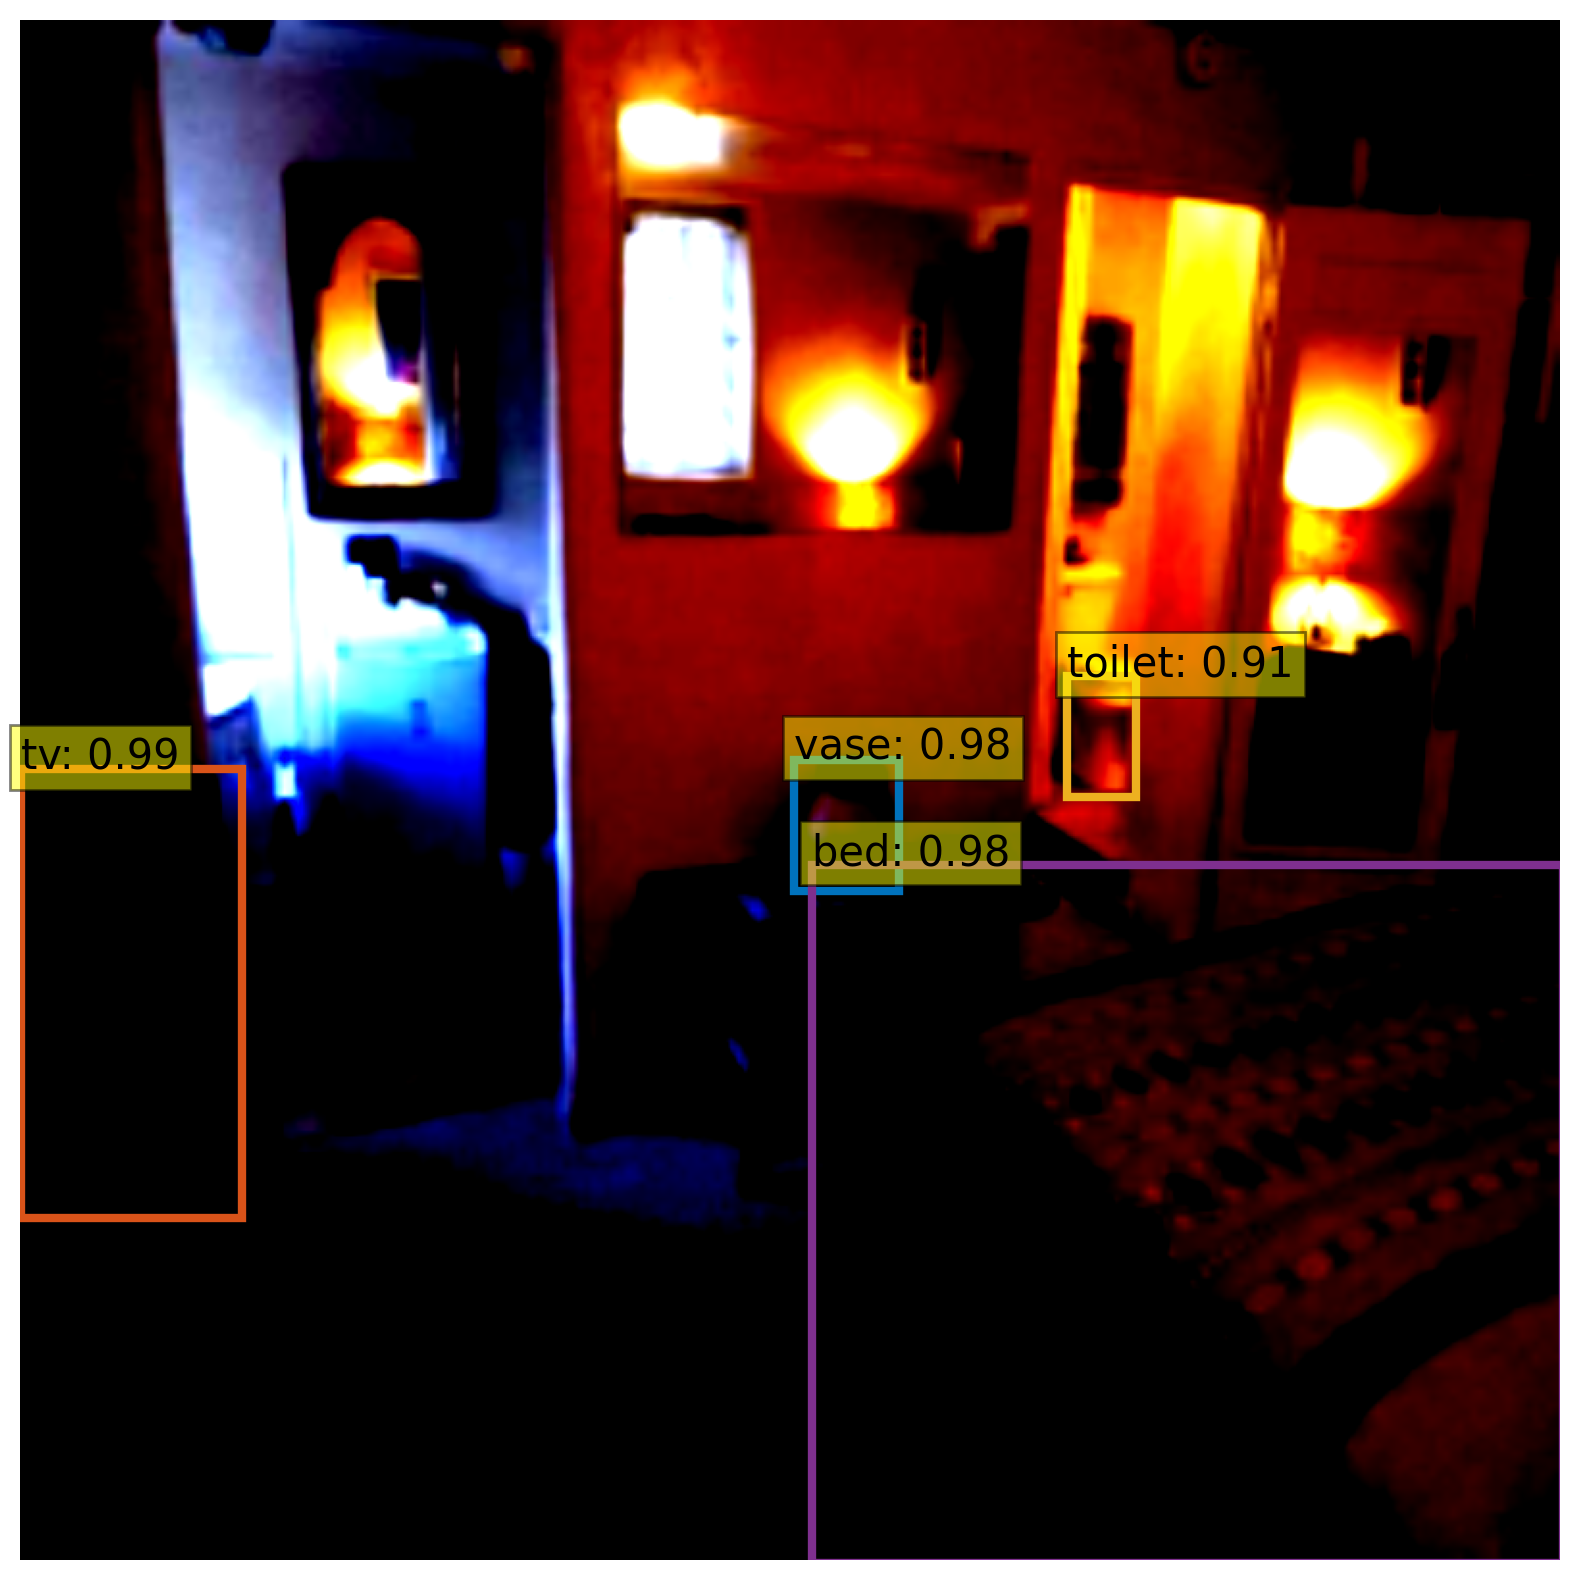

In [21]:
import numpy as np
import matplotlib.pyplot as plt

example_counter = 0
for image, data in inference_loader:
    if example_counter >= num_of_examples:
        break
    print("Image shape: ", image.shape)
    image = image[0]
    print("Image shape after selection: ", image.shape)

    processed_image = transform(image)
    outputs = model(processed_image.unsqueeze(0))

    probas = outputs['pred_logits'].softmax(-1)[0, :, :-1]
    keep = probas.max(-1).values > 0.7

    img = processed_image.detach().cpu().numpy()
    img = img.transpose(1, 2, 0)
    img = np.clip(img, 0, 1)
    # convert boxes from [0; 1] to image scales
    bboxes_scaled = rescale_bboxes(outputs['pred_boxes'][0, keep], processed_image.shape[1:])

    plot_results(img, probas[keep], bboxes_scaled)

    example_counter += 1